### Language Identification -- Building Statistical Classifiers

Zoey Liu

In this notebook, we will play around with building statistical classifiers to do language identification using part-of-speech (POS) tags.

In [20]:
# Loading some packages
# Make sure to install the packages if you run into errors
# !pip install PACKAGE_NAME
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

I picked (simplified) Mandarin Chinese, because! And also Basque --- the endlessly interesting "alien language". We would be only using the output files for both here (each line of the output file contains the POS tag sequence for the corresponding line of the input file).

Let's start with looking at our data.

In [21]:
!head ../data/POS_data/UD_Basque/train.output

NOUN NOUN ADP DET NOUN VERB AUX PUNCT NOUN ADJ NUM CCONJ PUNCT CCONJ ADJ NOUN PROPN ADJ CCONJ DET DET NOUN CCONJ PUNCT
VERB VERB AUX NOUN DET ADP VERB PUNCT
PROPN NOUN NOUN VERB NOUN DET PUNCT
ADJ NOUN PROPN PROPN VERB AUX PUNCT NUM PUNCT CCONJ ADJ PROPN PROPN PUNCT NUM PUNCT PUNCT
NOUN NOUN ADJ NOUN NOUN PUNCT NOUN ADJ PUNCT VERB NOUN PUNCT NOUN ADJ DET NOUN CCONJ NOUN NOUN ADJ PUNCT VERB AUX PUNCT
PROPN NOUN PROPN VERB AUX NOUN PROPN PROPN ADJ ADJ NOUN VERB PUNCT DET NOUN VERB NOUN PUNCT
CCONJ DET NOUN VERB NOUN CCONJ NOUN PUNCT NOUN ADP PUNCT
PART PART AUX ADJ NOUN VERB NOUN ADJ PUNCT
NUM ADJ NUM VERB AUX NOUN PUNCT
NOUN ADJ NUM VERB CCONJ NOUN ADJ VERB NOUN NUM NOUN NUM VERB VERB AUX PUNCT


In [22]:
!head ../data/POS_data/UD_Chinese/train.output

PROPN ADP PROPN CCONJ PROPN VERB SCONJ VERB PART NOUN AUX NUM NOUN PART NOUN NOUN PUNCT
NOUN VERB VERB NOUN NOUN NOUN ADP NOUN NOUN PUNCT NOUN ADV VERB VERB PUNCT NOUN ADV VERB NOUN VERB PUNCT VERB AUX NOUN PROPN PART NOUN PUNCT
PROPN PART PROPN PART NOUN VERB ADJ SCONJ NOUN PUNCT PROPN PRON AUX NOUN PART PUNCT SCONJ PRON PART PART NOUN SCONJ VERB NOUN PROPN NOUN PUNCT
PRON NOUN PROPN ADP NOUN PROPN NOUN NOUN VERB PUNCT
VERB VERB PART CCONJ VERB NOUN SCONJ NOUN SCONJ VERB PUNCT NOUN PUNCT AUX NOUN PUNCT VERB PROPN PART NOUN NOUN PUNCT
PROPN PART VERB PUNCT PROPN PART SCONJ ADP NOUN NOUN VERB NOUN PUNCT PROPN PROPN ADP PROPN PROPN VERB PUNCT
NUM NOUN NOUN ADP PUNCT PROPN PROPN NUM NOUN VERB PUNCT PROPN NOUN PUNCT PUNCT
NOUN PUNCT AUX NOUN PART NOUN PART NOUN NOUN NOUN PART PART NOUN NUM NOUN PUNCT VERB ADP PROPN PART PROPN PART NOUN PUNCT NOUN AUX VERB NUM NOUN PUNCT VERB ADP NOUN VERB SCONJ ADJ NOUN PUNCT VERB ADJ PART PUNCT ADV VERB NOUN AUX NOUN PUNCT AUX VERB VERB VERB PART CCONJ VE

In [23]:
## Loading the data
def load_pos_data(file_path):
    data = []
    with open(file_path, 'r', encoding='utf-8') as f:
        for line in f:
            tag_list = line.strip().split()
            data.append(tag_list)
    return data

In [24]:
# Basque data
basque_pos_data = load_pos_data('../data/POS_data/UD_Basque/train.output')

# Chinese data
chinese_pos_data = load_pos_data('../data/POS_data/UD_Chinese/train.output')
chinese_pos_data

[['PROPN',
  'ADP',
  'PROPN',
  'CCONJ',
  'PROPN',
  'VERB',
  'SCONJ',
  'VERB',
  'PART',
  'NOUN',
  'AUX',
  'NUM',
  'NOUN',
  'PART',
  'NOUN',
  'NOUN',
  'PUNCT'],
 ['NOUN',
  'VERB',
  'VERB',
  'NOUN',
  'NOUN',
  'NOUN',
  'ADP',
  'NOUN',
  'NOUN',
  'PUNCT',
  'NOUN',
  'ADV',
  'VERB',
  'VERB',
  'PUNCT',
  'NOUN',
  'ADV',
  'VERB',
  'NOUN',
  'VERB',
  'PUNCT',
  'VERB',
  'AUX',
  'NOUN',
  'PROPN',
  'PART',
  'NOUN',
  'PUNCT'],
 ['PROPN',
  'PART',
  'PROPN',
  'PART',
  'NOUN',
  'VERB',
  'ADJ',
  'SCONJ',
  'NOUN',
  'PUNCT',
  'PROPN',
  'PRON',
  'AUX',
  'NOUN',
  'PART',
  'PUNCT',
  'SCONJ',
  'PRON',
  'PART',
  'PART',
  'NOUN',
  'SCONJ',
  'VERB',
  'NOUN',
  'PROPN',
  'NOUN',
  'PUNCT'],
 ['PRON',
  'NOUN',
  'PROPN',
  'ADP',
  'NOUN',
  'PROPN',
  'NOUN',
  'NOUN',
  'VERB',
  'PUNCT'],
 ['VERB',
  'VERB',
  'PART',
  'CCONJ',
  'VERB',
  'NOUN',
  'SCONJ',
  'NOUN',
  'SCONJ',
  'VERB',
  'PUNCT',
  'NOUN',
  'PUNCT',
  'AUX',
  'NOUN',
  'PUNCT

Now we have our **text data**, we need to extract some features to build the classifiers. Recall that these features are subjective --- you can decide the feature set and extract whatever you'd like.

We will start with some frequency/probability distribution.

In [25]:
# We first need a function to identify all the unique POS tags in a given dataset
def get_unique_pos_tags(data):
    unique_tags = set()
    for sentence in data:
        unique_tags.update(sentence)
    return sorted(list(unique_tags))

In [26]:
# Extracting probability distribution features
basque_unique_tags = get_unique_pos_tags(basque_pos_data)
basque_unique_tags

['ADJ',
 'ADP',
 'ADV',
 'AUX',
 'CCONJ',
 'DET',
 'INTJ',
 'NOUN',
 'NUM',
 'PART',
 'PRON',
 'PROPN',
 'PUNCT',
 'VERB',
 'X']

In [27]:
chinese_unique_tags = get_unique_pos_tags(chinese_pos_data)
chinese_unique_tags

['ADJ',
 'ADP',
 'ADV',
 'AUX',
 'CCONJ',
 'DET',
 'NOUN',
 'NUM',
 'PART',
 'PRON',
 'PROPN',
 'PUNCT',
 'SCONJ',
 'VERB',
 'X']

Combining unique tags of the two languages

QUESTION: WHY?

> To get all the tags in both corpora. Since the task is language identification using POS features, if a tag is in one language vs not in another, then that should contribute to how the classifiers learn.

In [28]:
combined_unique_tags = sorted(list(set(basque_unique_tags).union(set(chinese_unique_tags))))
combined_unique_tags

['ADJ',
 'ADP',
 'ADV',
 'AUX',
 'CCONJ',
 'DET',
 'INTJ',
 'NOUN',
 'NUM',
 'PART',
 'PRON',
 'PROPN',
 'PUNCT',
 'SCONJ',
 'VERB',
 'X']

In [29]:
# We then convert the POS tag sequences to feature vectors
def pos_tags_to_prob(pos_sequence, unique_tags):
    """Convert POS tag sequence to feature vector (normalized distribution)"""
    total = len(pos_sequence)
    counts = Counter(pos_sequence)
    features = [counts.get(tag, 0) / total for tag in unique_tags]
    return features

In [30]:
basque_features = [pos_tags_to_prob(sent, combined_unique_tags) for sent in basque_pos_data]
chinese_features = [pos_tags_to_prob(sent, combined_unique_tags) for sent in chinese_pos_data]
chinese_features

[[0.0,
  0.058823529411764705,
  0.0,
  0.058823529411764705,
  0.058823529411764705,
  0.0,
  0.0,
  0.23529411764705882,
  0.058823529411764705,
  0.11764705882352941,
  0.0,
  0.17647058823529413,
  0.058823529411764705,
  0.058823529411764705,
  0.11764705882352941,
  0.0],
 [0.0,
  0.03571428571428571,
  0.07142857142857142,
  0.03571428571428571,
  0.0,
  0.0,
  0.0,
  0.39285714285714285,
  0.0,
  0.03571428571428571,
  0.0,
  0.03571428571428571,
  0.14285714285714285,
  0.0,
  0.25,
  0.0],
 [0.037037037037037035,
  0.0,
  0.0,
  0.037037037037037035,
  0.0,
  0.0,
  0.0,
  0.2222222222222222,
  0.0,
  0.18518518518518517,
  0.07407407407407407,
  0.14814814814814814,
  0.1111111111111111,
  0.1111111111111111,
  0.07407407407407407,
  0.0],
 [0.0,
  0.1,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.4,
  0.0,
  0.0,
  0.1,
  0.2,
  0.1,
  0.0,
  0.1,
  0.0],
 [0.0,
  0.0,
  0.0,
  0.045454545454545456,
  0.045454545454545456,
  0.0,
  0.0,
  0.2727272727272727,
  0.0,
  0.0909090909

In [31]:
# Let's take a look at the features
for i in range(3):
    print(f"Basque sentence {i+1} features: {basque_features[i]}")

print('\n')
print('\n')
for i in range(3):
    print(f"Chinese sentence {i+1} features: {chinese_features[i]}")

# For classifications, recall that we often work with arrays/matrices
# This will be the input, X, to the classifiers
basque_X_features = np.array(basque_features)
chinese_X_features = np.array(chinese_features)

Basque sentence 1 features: [0.125, 0.041666666666666664, 0.0, 0.041666666666666664, 0.16666666666666666, 0.125, 0.0, 0.25, 0.041666666666666664, 0.0, 0.0, 0.041666666666666664, 0.125, 0.0, 0.041666666666666664, 0.0]
Basque sentence 2 features: [0.0, 0.125, 0.0, 0.125, 0.0, 0.125, 0.0, 0.125, 0.0, 0.0, 0.0, 0.0, 0.125, 0.0, 0.375, 0.0]
Basque sentence 3 features: [0.0, 0.0, 0.0, 0.0, 0.0, 0.14285714285714285, 0.0, 0.42857142857142855, 0.0, 0.0, 0.0, 0.14285714285714285, 0.14285714285714285, 0.0, 0.14285714285714285, 0.0]




Chinese sentence 1 features: [0.0, 0.058823529411764705, 0.0, 0.058823529411764705, 0.058823529411764705, 0.0, 0.0, 0.23529411764705882, 0.058823529411764705, 0.11764705882352941, 0.0, 0.17647058823529413, 0.058823529411764705, 0.058823529411764705, 0.11764705882352941, 0.0]
Chinese sentence 2 features: [0.0, 0.03571428571428571, 0.07142857142857142, 0.03571428571428571, 0.0, 0.0, 0.0, 0.39285714285714285, 0.0, 0.03571428571428571, 0.0, 0.03571428571428571, 0.14285

In [32]:
# Creating arrays for the labels, y
# Let's set Basque as 0 and Chinese as 1
# But this is arbitrary, you can choose whatever you'd like
basque_y = np.zeros(len(basque_X_features))
chinese_y = np.ones(len(chinese_X_features))
chinese_y

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1.

In [33]:
# Combine the data
X = np.vstack((basque_X_features, chinese_X_features))
X

array([[0.125     , 0.04166667, 0.        , ..., 0.        , 0.04166667,
        0.        ],
       [0.        , 0.125     , 0.        , ..., 0.        , 0.375     ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.14285714,
        0.        ],
       ...,
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.02702703, 0.13513514, 0.02702703, ..., 0.08108108, 0.10810811,
        0.        ],
       [0.        , 0.0952381 , 0.04761905, ..., 0.        , 0.14285714,
        0.        ]], shape=(671, 16))

In [34]:
y = np.concatenate((basque_y, chinese_y))
y

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0.

In [35]:
# Create DataFrame for visualization to see if we have everything right
df = pd.DataFrame(X, columns=combined_unique_tags)
df['language'] = ['Basque'] * len(basque_features) + ['Chinese'] * len(chinese_features)

print("="*60)
print("BINARY CLASSIFICATION: ENGLISH vs JAPANESE")
print("="*60)
print(f"\nDataset shape: {X.shape}")
print(f"Number of features (POS tags): {X.shape[1]}")
print(f"Basque samples: {len(basque_features)}")
print(f"Chinese samples: {len(chinese_features)}")


BINARY CLASSIFICATION: ENGLISH vs JAPANESE

Dataset shape: (671, 16)
Number of features (POS tags): 16
Basque samples: 435
Chinese samples: 236


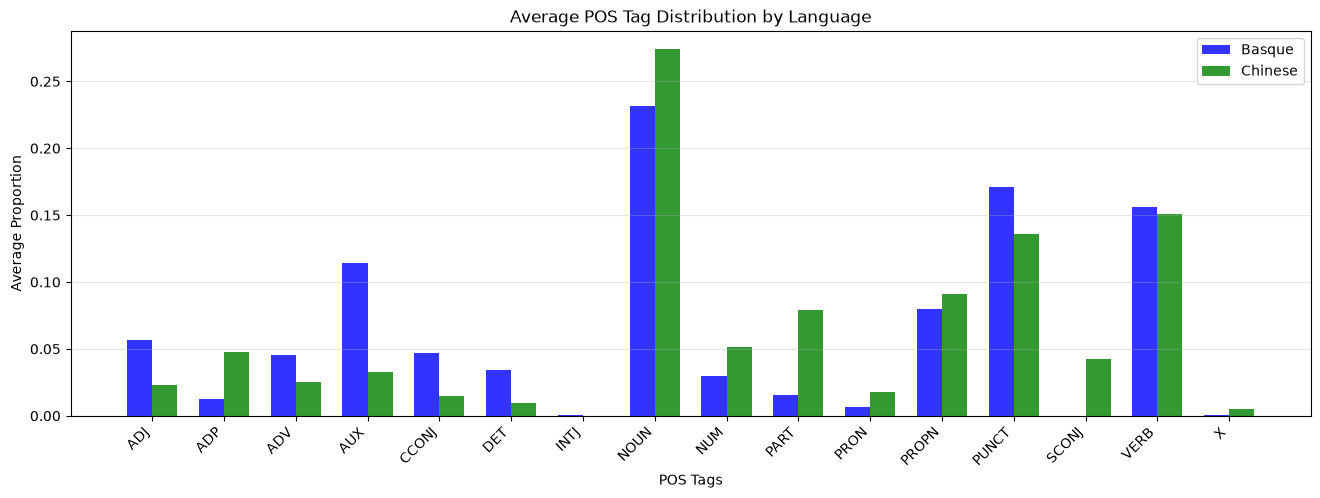

In [36]:
# Visualize POS tag distributions
fig, axes = plt.subplots(1, 1, figsize=(16, 5))

# Average distribution for each language
avg_basque = basque_X_features.mean(axis=0)
avg_chinese = chinese_X_features.mean(axis=0)

x_pos = np.arange(len(combined_unique_tags))
width = 0.35

axes.bar(x_pos - width/2, avg_basque, width, label='Basque', alpha=0.8, color='blue')
axes.bar(x_pos + width/2, avg_chinese, width, label='Chinese', alpha=0.8, color='green')
axes.set_xlabel('POS Tags')
axes.set_ylabel('Average Proportion')
axes.set_title('Average POS Tag Distribution by Language')
axes.set_xticks(x_pos)
axes.set_xticklabels(combined_unique_tags, rotation=45, ha='right')
axes.legend()
axes.grid(axis='y', alpha=0.3)

For any model training and evaluation, we need a training set and a test set. In this case we will randomly split each POS feature set into training and test setes.

In [37]:
# Randomly split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=10, stratify=y
)

print(f"\nTraining set size: {len(X_train)}")
print(f"Test set size: {len(X_test)}")


Training set size: 536
Test set size: 135



Accuracy: 0.874

Classification Report:
              precision    recall  f1-score   support

      Basque       0.84      0.99      0.91        88
     Chinese       0.97      0.66      0.78        47

    accuracy                           0.87       135
   macro avg       0.91      0.82      0.85       135
weighted avg       0.89      0.87      0.87       135



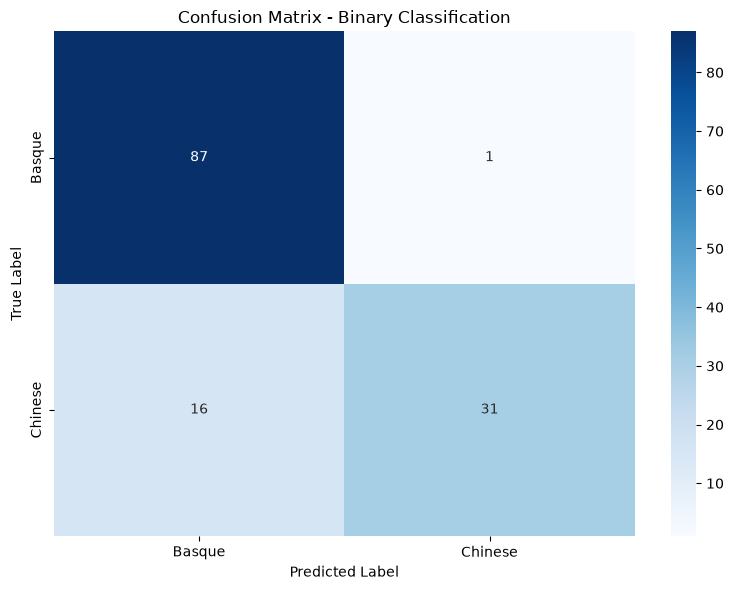

In [39]:
# Train logistic regression
lr_binary = LogisticRegression(random_state=1, max_iter=1000)
lr_binary.fit(X_train, y_train)

# Predictions
y_pred = lr_binary.predict(X_test)
y_pred_proba = lr_binary.predict_proba(X_test)

print(f"\nAccuracy: {accuracy_score(y_test, y_pred):.3f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Basque', 'Chinese']))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Basque', 'Chinese'],
            yticklabels=['Basque', 'Chinese'])
plt.title('Confusion Matrix - Binary Classification')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.show()

QUESTIONS: 

(1) What do the results tell you?

- > TP: 31 is the LR model correctly predicts Chinese language
- > FN: 16 is the LR model incorrecly predicts Basque language. It should predict Chinese, thus misses out.
- > TN: 87 is the LR model correctly predicts Basque language.
- > FP: 1 is the LR model incorrectly predicts Chinese language. It should predict Basque, thus inflates.

(2) How would we know the models have *learned* something?

- > When there's high precision and recall
- > $$ p = tp / (tp + fp) \Rightarrow 31 / (31 + 1) \Rightarrow 31 / 32 = 0.969 $$
- > $$ r = tp / (tp + fn) \Rightarrow 31 / (31 + 16) \Rightarrow 31 / 47 = 0.660 $$
- > precision derives from the FP, so model learns if there's a low rate of FP, which then increase the rate of precision. Here, 1 FP $ \rightarrow $ 96% for precision.
- > recall derives from the FN, so model learns if there's a low rate of FN, which then increase the rate of recall. Here, 16 FN $ \rightarrow $ 66%% for recall.

In [40]:
# Majority Class Baseline
from sklearn.dummy import DummyClassifier

majority_clf = DummyClassifier(strategy='most_frequent', random_state=6)
majority_clf.fit(X_train, y_train)
y_pred_majority = majority_clf.predict(X_test)
acc_majority = accuracy_score(y_test, y_pred_majority)
print(f"\nMajority Class Baseline: {acc_majority:.3f}")


Majority Class Baseline: 0.652


QUESTION: What is 0.652?

> The accuracy score where the dummy classifier predicts the same label (which represents the language) as the ground truth.

In [41]:
round(88 / (88+47), 3)

0.652

Explainability is important. Period. What features help the most with distinguishing between Basque vs. Chinese?


- > POS tags  for (+) class: PART > SCONJ > ADP
- > POS tags  for (-) class: AUX < ADJ < CCONJ
- > The reason could be because...


Feature Importance (Coefficients):
   POS_tag  coefficient
9     PART     4.550429
13   SCONJ     3.442093
1      ADP     2.457880
8      NUM     1.637224
7     NOUN     1.604739
10    PRON     0.767283
11   PROPN     0.525921
15       X     0.449702
6     INTJ    -0.037053
14    VERB    -0.354768
2      ADV    -0.913714
5      DET    -1.737277
12   PUNCT    -1.874266
4    CCONJ    -2.531682
0      ADJ    -2.546074
3      AUX    -5.433336


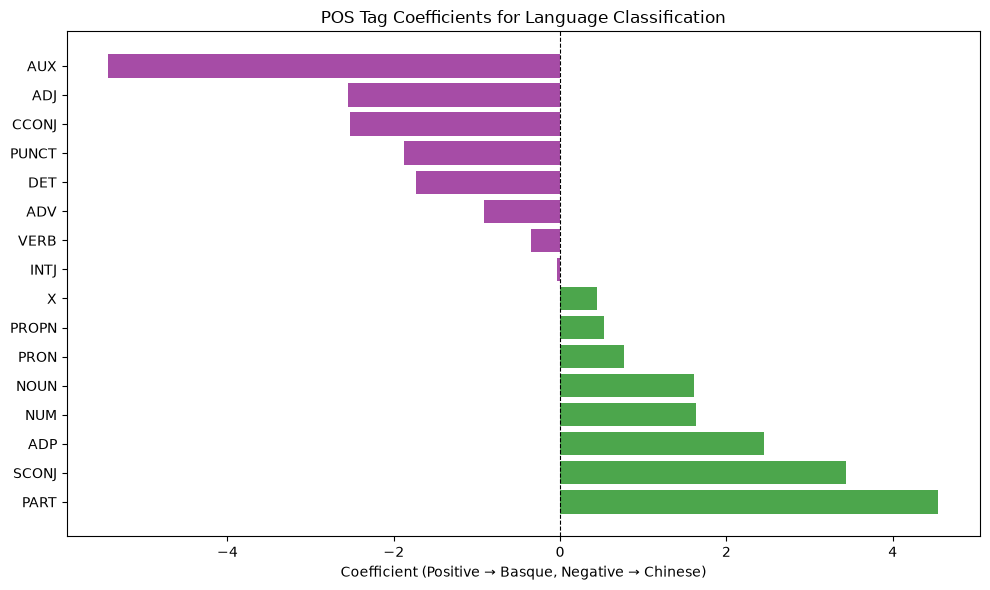

In [42]:
# Feature importance
coefficients = lr_binary.coef_[0]
feature_importance = pd.DataFrame({
    'POS_tag': combined_unique_tags,
    'coefficient': coefficients
}).sort_values('coefficient', ascending=False)

print("\nFeature Importance (Coefficients):")
print(feature_importance)

plt.figure(figsize=(10, 6))
colors = ['green' if c > 0 else 'purple' for c in feature_importance['coefficient']]
plt.barh(feature_importance['POS_tag'], feature_importance['coefficient'], color=colors, alpha=0.7)
plt.xlabel('Coefficient (Positive → Basque, Negative → Chinese)')
plt.title('POS Tag Coefficients for Language Classification')
plt.axvline(x=0, color='black', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.show()

"Positive → Basque, Negative → Chinese", so Basque is green and Chinese is purple
- > POS tags  for basque class: PART > SCONJ > ADP
    - > PART is surprisingly the most important/explainable feature because it's distribution is amongst the lower ones. This shows that the Basque languge heavily relys on this POS tag despite it not occuring as often as other POS tag.
- > POS tags  for (-) class: AUX < ADJ < CCONJ
    - > AUX is quite similar to PART for Basque. 

- > Since the distribution of both PART in Basque and AUX in Chinese are low, we may be able to say that there is not much noise. A larger distribution for either could lead to more noise and not have them contribute as much. The few PART and AUX tags shows that specific influential cases were in the datasets.


## Exercise:

Use the data from `UD_Arabic` and `UD_Turkish` to build a logistic regression classifier that does multi-class classification.

In [43]:
# Basque data
arabic_pos_data = load_pos_data('../data/POS_data/UD_Arabic/train.output')

# Chinese data
turkish_pos_data = load_pos_data('../data/POS_data/UD_Turkish/train.output')
turkish_pos_data

[['ADV', 'PUNCT', 'ADJ', 'NOUN', 'AUX', 'PUNCT'],
 ['PRON', 'NOUN', 'NOUN', 'ADV', 'VERB', 'PUNCT'],
 ['NOUN', 'NOUN', 'NOUN', 'NOUN', 'AUX', 'PUNCT'],
 ['NOUN',
  'ADJ',
  'ADJ',
  'ADJ',
  'NOUN',
  'NOUN',
  'NOUN',
  'NUM',
  'NUM',
  'NOUN',
  'CCONJ',
  'PROPN',
  'PROPN',
  'NOUN',
  'NOUN',
  'NOUN',
  'ADP',
  'NOUN',
  'DET',
  'NOUN',
  'VERB',
  'PUNCT'],
 ['NOUN',
  'ADV',
  'PUNCT',
  'NUM',
  'NUM',
  'NOUN',
  'NOUN',
  'NOUN',
  'NOUN',
  'VERB',
  'PUNCT'],
 ['PROPN', 'PROPN', 'NOUN', 'NOUN', 'NUM', 'NOUN', 'VERB', 'PUNCT'],
 ['PROPN', 'PROPN', 'NOUN', 'PROPN', 'NUM', 'NUM', 'VERB', 'PUNCT'],
 ['DET',
  'NOUN',
  'NOUN',
  'ADJ',
  'NOUN',
  'NOUN',
  'ADP',
  'NOUN',
  'NOUN',
  'NOUN',
  'NOUN',
  'VERB',
  'PUNCT'],
 ['ADJ',
  'DET',
  'NOUN',
  'PUNCT',
  'PROPN',
  'NOUN',
  'ADJ',
  'NUM',
  'NOUN',
  'VERB',
  'PUNCT'],
 ['NOUN', 'VERB', 'PUNCT'],
 ['DET', 'NOUN', 'ADV', 'ADV', 'VERB', 'PUNCT'],
 ['PRON',
  'NOUN',
  'PUNCT',
  'ADJ',
  'NOUN',
  'CCONJ',
  'NO

In [44]:
# Extracting probability distribution features
arabic_unique_tags = get_unique_pos_tags(arabic_pos_data)
turkish_unique_tags = get_unique_pos_tags(turkish_pos_data)

# Combining unique tags of the two languages
# QUESTION: WHY?
combined_unique_tags = sorted(list(set(arabic_unique_tags).union(set(turkish_unique_tags))))

arabic_features = [pos_tags_to_prob(sent, combined_unique_tags) for sent in arabic_pos_data]
turkish_features = [pos_tags_to_prob(sent, combined_unique_tags) for sent in turkish_pos_data]

# Let's take a look at the features
for i in range(3):
    print(f"Basque sentence {i+1} features: {arabic_features[i]}")

print('\n')
print('\n')
for i in range(3):
    print(f"Chinese sentence {i+1} features: {turkish_features[i]}")

# For classifications, recall that we often work with arrays/matrices
# This will be the input, X, to the classifiers
arabic_X_features = np.array(arabic_features)
turkish_X_features = np.array(turkish_features)

Basque sentence 1 features: [0.05555555555555555, 0.16666666666666666, 0.0, 0.0, 0.1111111111111111, 0.05555555555555555, 0.0, 0.16666666666666666, 0.0, 0.0, 0.0, 0.0, 0.16666666666666666, 0.05555555555555555, 0.0, 0.05555555555555555, 0.16666666666666666]
Basque sentence 2 features: [0.06060606060606061, 0.24242424242424243, 0.0, 0.0, 0.06060606060606061, 0.09090909090909091, 0.0, 0.30303030303030304, 0.030303030303030304, 0.0, 0.06060606060606061, 0.0, 0.030303030303030304, 0.030303030303030304, 0.0, 0.09090909090909091, 0.0]
Basque sentence 3 features: [0.15384615384615385, 0.23076923076923078, 0.0, 0.0, 0.07692307692307693, 0.0, 0.0, 0.38461538461538464, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.07692307692307693, 0.07692307692307693]




Chinese sentence 1 features: [0.16666666666666666, 0.0, 0.16666666666666666, 0.16666666666666666, 0.0, 0.0, 0.0, 0.16666666666666666, 0.0, 0.0, 0.0, 0.0, 0.3333333333333333, 0.0, 0.0, 0.0, 0.0]
Chinese sentence 2 features: [0.0, 0.0, 0.1666666666666666

In [45]:
arabic_y = np.zeros(len(arabic_X_features))
turkish_y = np.ones(len(turkish_X_features))

In [46]:
# Combine the data
X = np.vstack((arabic_X_features, turkish_X_features))
y = np.concatenate((arabic_y, turkish_y))

In [47]:
# Randomly split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=10, stratify=y
)

print(f"\nTraining set size: {len(X_train)}")
print(f"Test set size: {len(X_test)}")


Training set size: 363
Test set size: 91



Accuracy: 0.923

Classification Report:
              precision    recall  f1-score   support

      Basque       1.00      0.77      0.87        31
     Chinese       0.90      1.00      0.94        60

    accuracy                           0.92        91
   macro avg       0.95      0.89      0.91        91
weighted avg       0.93      0.92      0.92        91



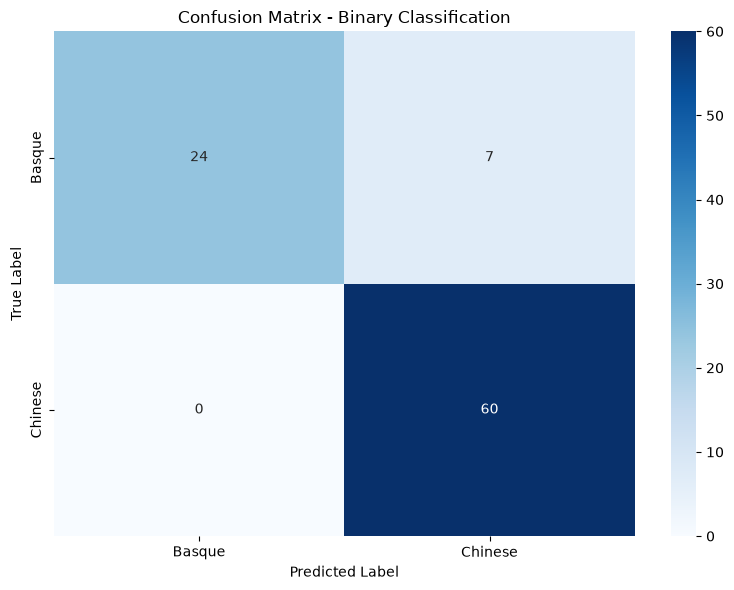

In [51]:
# Train logistic regression
lr = LogisticRegression(random_state=1, max_iter=1000, solver='lbfgs')
lr.fit(X_train, y_train)

# Predictions
y_pred = lr.predict(X_test)
y_pred_proba = lr.predict_proba(X_test)

print(f"\nAccuracy: {accuracy_score(y_test, y_pred):.3f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Basque', 'Chinese']))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Basque', 'Chinese'],
            yticklabels=['Basque', 'Chinese'])
plt.title('Confusion Matrix - Binary Classification')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.show()